# 3Gyr Escaped Asteroid Analysis mc_pm6_3 
This notebooks is in preparation for the 3Gyr analysis and the new luthera family dataframe that includes more orbital information.

The run_log_analysis python script summarises the hdf5 log files into an escaped_asteroids pandas DataFrame. 

This DataFrame has details of the parameter and time that the asteroid exceeds the various parameters that are monitored. 


In [1]:
import datetime as datetime
from pathlib import Path

import pandas as pd
import numpy as np
import h5py as h5

import scipy
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import cm

xlabel_time = 'Years after start of simulation [$10^9 ~ yr$]'

project_dir = Path('../../asteroid_data/mc_pm6_3/')

In [2]:
# Read the escaped asteroids file
ea_mmc3 = pd.read_hdf(project_dir / 'escaped_asteroids.h5')

# Strip the spaces out of the names of the asteroids
ea_mmc3['ast_name'] = [x.replace(' ','') for x in ea_mmc3.ast_name]

ea_mmc3.describe()

,particle_number,parameter,parameter_value,integration_year,min_val,max_val
count,36087.000000,36087.000000,36087.000000,3.608700e+04,36087.000000,36087.000000
mean,9.145648,6.716574,2.463010,5.643052e+09,0.319788,5.296246
std,0.837261,0.752043,5.720012,5.648621e+09,1.190401,10.044900
min,8.000000,6.000000,-2.071092,1.000000e+04,-153.251723,0.340019
25%,8.000000,6.000000,0.340329,6.726912e+08,0.000000,0.782868
50%,9.000000,7.000000,0.393295,3.442278e+09,0.000000,1.266282
75%,10.000000,7.000000,0.790637,9.770382e+09,0.046305,3.242661
max,10.000000,8.000000,98.535587,1.884954e+10,3.902529,98.535587


In [3]:
print(f"Mars/Ceres Mercurious escaped test-particles:{(ea_mmc3.ast_name+ea_mmc3['vectors']).nunique()}")


Mars/Ceres Mercurious escaped test-particles:19771


In [4]:
new_fam_dir = Path('../../luthera_ast/')
plot_dir = project_dir / 'plots'

luth_proper_h5 = new_fam_dir / 'luther_proper.h5'
luth_fam = pd.read_hdf(luth_proper_h5)

luth_fam['irad'] = np.arcsin(luth_fam['sineI_P'])
luth_fam['ideg'] = np.degrees(luth_fam['irad'])

mag_h = 17
p_v = 0.0387

luth_fam['diam']= ((1329 * 10**(-luth_fam['abs_mag']/5)) * (p_v ** (-0.5)))
luth_fam = luth_fam.set_index('ast_name')
luth_fam.describe()

,abs_mag,a_P,e_P,sineI_P,n,g,s,lyap_time,My_int_time,irad,ideg,diam
count,878.000000,878.000000,878.000000,878.000000,878.000000,878.000000,878.000000,878.000000,878.0,878.000000,878.000000,878.000000
mean,16.175513,3.208147,0.123992,0.323863,62.636725,163.961034,-74.485114,259.071526,-10.0,0.329816,18.897053,4.478502
std,0.987079,0.014558,0.008572,0.005743,0.426461,57.980031,1.524164,752.086762,0.0,0.006072,0.347883,3.757710
min,9.480000,3.172780,0.106420,0.312013,61.765176,85.871008,-79.056097,5.500000,-10.0,0.317312,18.180615,1.752546
25%,15.620000,3.196843,0.117742,0.320017,62.306345,118.604830,-75.573336,29.200000,-10.0,0.325747,18.663932,2.829238
50%,16.390000,3.207515,0.123102,0.323137,62.653273,146.082211,-74.454953,82.950000,-10.0,0.329043,18.852771,3.561800
75%,16.890000,3.219394,0.129977,0.327705,62.966784,194.958434,-73.310560,250.000000,-10.0,0.333874,19.129562,5.077729
max,17.930000,3.238196,0.144674,0.340954,63.701778,361.322776,-71.181669,10000.000000,-10.0,0.347932,19.935032,85.836005


In [5]:
old_luth_h5 = '../../asteroid_data/luthera_family.h5'

old_luth_fam = pd.read_hdf(old_luth_h5)
old_luth_fam = old_luth_fam.set_index('ast_name')
old_luth_fam.describe()

,abs_mag,a_P,e_P,sineI_P
count,878.000000,878.000000,878.000000,878.000000
mean,16.175513,3.208147,0.123992,0.323863
std,0.987079,0.014558,0.008572,0.005743
min,9.480000,3.172780,0.106420,0.312013
25%,15.620000,3.196843,0.117742,0.320017
50%,16.390000,3.207515,0.123103,0.323137
75%,16.890000,3.219394,0.129976,0.327705
max,17.930000,3.238196,0.144674,0.340954


## Data issues !!!
The proper elements (from afp.num.pro.txt and afp.mult.pro.txt) were merged into the family data (afp.fam.members.txt)
to provide the perihelion an nodal precessions (g and s).

We now have unmatched asteroids coming back from the simulations as they were run with the old asteroid designations.

From the afp.fam.members.txt dated 2023AUG08

| Asteroid designation | Absolute Mag | Proper SMA | Proper Eccentricity | Proper Sin i | Family ID |
| --- | --- | --- | --- | --- | --- |
|  2017AC51 |  17.41   |   3.172780   |   0.120229   |   0.321580   |   1303 |

From the afp.fam.members.txt dated 2023FEB27
| Asteroid designation | Absolute Mag | Proper SMA | Proper Eccentricity | Proper Sin i | Family ID |
| --- | --- | --- | --- | --- | --- |
| 2010VV146  |  17.41   |   3.172780   |   0.120229   |   0.321580    |  1303 |


From the afp.mult.pro.txt dated 2023AUG09

| Asteroid designation | Absolute Mag | Proper SMA | Proper Eccentricity | Proper Sin i | n | g | s | lyap time | My Int Time |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 2017AC51  |   17.41  | 3.1727797 | 0.1202292 | 0.3215795  | 63.701778  |  85.871008  | -71.650735  |     14.9  |  -10 |
| 2010VV146  |  17.83  | 2.8051083 | 0.1852427 | 0.0790516  | 76.607069  |  68.027468  | -72.775633   |   243.9   | -10 |

There are 


In [6]:
# Extract the unique ast_names
family_asts = luth_fam.index.unique()
# Extract the unique ast_names
old_family_asts = old_luth_fam.index.unique()

# get the list of asteroids that remained the same
in_common = family_asts.intersection(old_family_asts)

# Find the ones that are not in both (these are the duplicates)
old_missing = old_luth_fam.index.difference(in_common)
new_missing = luth_fam.index.difference(in_common)

# Sort the values by semi major axis and eccentricity to line up the asteroids with the same values
old_sort = old_luth_fam[old_luth_fam.index.isin(old_missing)].sort_values(['a_P','e_P'])
new_sort = luth_fam[luth_fam.index.isin(new_missing)].sort_values(['a_P','e_P'])

name_converter = [ (x[1], x[0]) for x in zip(list(new_sort.index),list(old_sort.index))]

#print(name_converter)
for convert in name_converter:
    # print(f'changing {convert[0]} to {convert[1]}')
    ea_mmc3.loc[(ea_mmc3.ast_name==convert[0]),'ast_name'] = convert[1]

ea_mmc3 = ea_mmc3.set_index('ast_name')

In [7]:
escaped_asts = ea_mmc3.index.unique()
print(f'Checking that all the escaped asts {len(escaped_asts)} = {len(luth_fam[luth_fam.index.isin(escaped_asts)==True])} are in the family')

Checking that all the escaped asts 691 = 690 are in the family


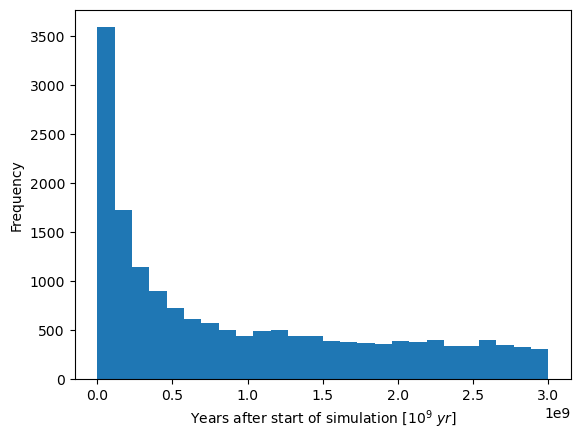

<BarContainer object of 26 artists>


In [8]:
escapee_years = ea_mmc3.loc[ea_mmc3.parameter == 6][['vectors', 'integration_year']]
escapee_years['integration_year'] = escapee_years.integration_year/(2*np.pi)
part_nums, t_values, what = plt.hist(escapee_years.integration_year, bins='auto')
plt.ylabel('Frequency')
plt.xlabel(xlabel_time)
plt.show()
print(what)

# Calculating half-life of test-particle orbital disruption

Using the standard radioactive decay formula of 

$N = N_0 ~e^{\frac{-0.693}{\tau}t}$

$N_0$ is the starting number of particles
$N$ is the remaining number of 

So we fit:  

$ln(\frac{N}{N_0}) = \frac{-0.693}{\tau}t$

$\frac{-0.693}{\tau} = \frac{ln(\frac{N}{N_0})}{t}$

$\tau = \frac{-0.693 \times t}{ln(\frac{N}{N_0})}$


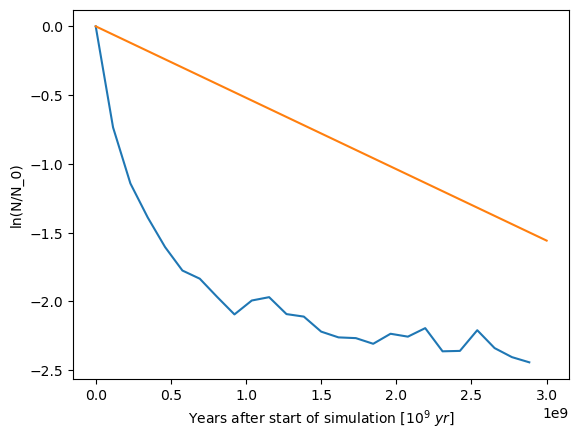


The tau=1.33e+09 yr and the 99.99% time is 1.77e+10 yr


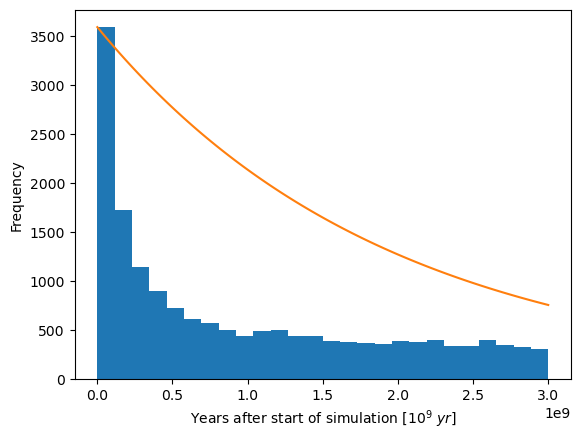

In [10]:
#print(part_nums, t_values)
# Get the ratio of the particles
n_0 = part_nums[0]

t_span = np.linspace(t_values[0], t_values[-1], 100)

# linerize the ratios
ln_part_ratios = np.log(part_nums/n_0)

part_fit = np.polynomial.Polynomial.fit(t_values[:-1], ln_part_ratios, 1)
k, a = part_fit.convert().coef
ln_fit = t_span*a

plt.plot(t_values[:-1], ln_part_ratios)
plt.plot(t_span, ln_fit)
plt.ylabel('ln(N/N_0)')
plt.xlabel(xlabel_time)
plt.show()


t=(-0.693/a)
t_span = np.linspace(t_values[0], t_values[-1], 100)
n_fit = n_0 * np.e**((-0.693/t)*t_span)

# Calc long 99.99% loss time
n_9999 = n_0 * (1.0-0.9999)
t_9999 = (t*np.log(n_9999/n_0))/-0.693
print()
print(f'The tau={t :0.2e} yr and the 99.99% time is {t_9999:0.2e} yr')

plt.hist(escapee_years.integration_year, bins='auto')
plt.plot(t_span, n_fit)
plt.ylabel('Frequency')
plt.xlabel(xlabel_time)
plt.show()

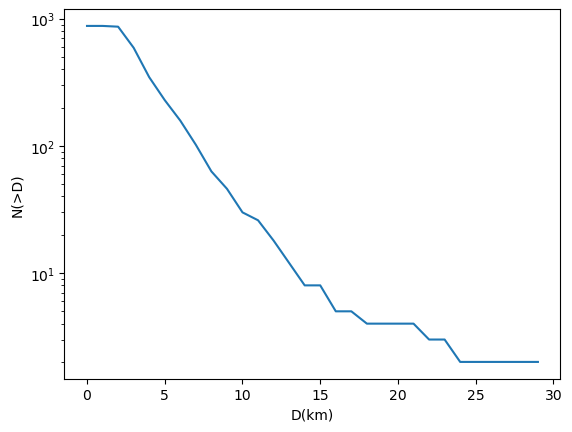

In [11]:
kms = list(range(0, 30)) #int(luth_fam.diam.max()+1)))
n_gt_km = [len(luth_fam[luth_fam.diam>km]) for km in kms]  
plt.plot(kms, n_gt_km)
plt.yscale('log')
plt.ylabel('N(>D)')
plt.xlabel('D(km)')
plt.show()

In [12]:
ey_years = escapee_years.groupby(by=escapee_years.index)
mean_escape = ey_years.mean('integration_year')
mean_escape['vec_count'] = ey_years.vectors.count()

print(escapee_years.head())

print(mean_escape.head())

                        vectors  integration_year
ast_name                                         
16794     XcpYcmZcpVXcpVYcmVZcp      9.881132e+07
499395    XcpYcmZcpVXcpVYcmVZcp      9.891133e+07
2017EV28  XcpYcmZcpVXcpVYcmVZcp      8.651010e+07
499395    XcmYcpZcmVXcmVYcpVZcp      1.802193e+08
2017EV28  XcmYcpZcmVXcmVYcpVZcp      2.360391e+07
          integration_year  vec_count
ast_name                             
104287        1.570929e+09         26
107448        1.854844e+09         15
111276        1.763208e+09         12
111798        1.948073e+09         10
113406        2.136745e+09          3


In [13]:
counts, bins = np.histogram(mean_escape.vec_count, 4)
mean_escape['quartiles'] = np.digitize(mean_escape.vec_count, bins)

In [14]:
luth_fam['integration_year'] = mean_escape.integration_year
luth_fam['quartiles'] = mean_escape.quartiles

luth_fam = luth_fam.fillna(value={'integration_year': 0, 'vec_count': 0})
luth_fam['graph_symbol'] = '.'
luth_fam.loc[luth_fam['integration_year']!=0,['graph_symbol']] = 'o'
len(luth_fam[luth_fam['integration_year']!=0])

luth_fam

,abs_mag,a_P,e_P,sineI_P,n,g,s,lyap_time,My_int_time,irad,ideg,diam,integration_year,quartiles,graph_symbol
ast_name,,,,,,,,,,,,,,,
1303,9.48,3.219248,0.121842,0.322276,62.310603,193.693422,-75.178531,500.0,-10,0.328133,18.800642,85.836005,2.467311e+09,1.0,o
11911,11.80,3.210027,0.132169,0.330567,62.579772,151.725694,-75.054158,48.8,-10,0.336904,19.303169,29.489642,2.288327e+09,1.0,o
16794,13.45,3.229767,0.120773,0.321221,62.006408,267.491465,-76.751030,87.7,-10,0.327018,18.736764,13.793342,9.323623e+08,2.0,o
17840,12.46,3.227073,0.122213,0.322861,62.084582,243.861008,-76.365994,123.5,-10,0.328751,18.836035,21.760531,1.555482e+09,2.0,o
26558,13.15,3.194646,0.115763,0.319342,63.032408,116.103022,-72.503135,27.1,-10,0.325035,18.623155,15.836875,0.000000e+00,NaN,.
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2021TA55,17.17,3.194082,0.114092,0.317706,63.048004,115.703831,-72.437569,53.8,-10,0.323309,18.524232,2.486964,2.539433e+09,1.0,o
2021TZ86,17.04,3.199622,0.138950,0.332601,62.884899,122.499167,-74.946763,625.0,-10,0.339060,19.426734,2.640399,3.910643e+08,4.0,o
2021UJ60,17.20,3.194881,0.135663,0.334094,63.027298,111.565516,-73.689163,24.4,-10,0.340644,19.517454,2.452842,1.150835e+09,3.0,o


In [15]:
def flash_plot(ax, ast_data, y_column, x_column='a_P'):
    for graph_symbol, m_fam in ast_data.groupby('graph_symbol'):
        if graph_symbol == '.':
            stab = ax.scatter(data=m_fam, x=x_column,y=y_column, edgecolors='white', marker='P', 
            c='black', label='Stable Asteroid')
        else:
            cm_yr = mpl.colormaps['inferno'] 
            norm_vecs = m_fam['quartiles']*40
            colour_values = m_fam['integration_year']
            esc = ax.scatter(data=m_fam, x=x_column,y=y_column, edgecolors='black', marker=graph_symbol, 
                c=colour_values, cmap = cm_yr, s=norm_vecs, label='Quartile')
                
            cb = plt.colorbar(esc, label=xlabel_time, location='bottom')
    
    esc_elements = esc.legend_elements("sizes", num=4)
    stab_elements = stab.legend_elements("sizes", num=1)
        
    plt.legend(handles = stab_elements[0] + esc_elements[0], 
               labels=['Stable', '<25% Clones', '25-50% Clones','51-75% Clones', '>75% Clones'],
               bbox_to_anchor=(1.0, 1.0))


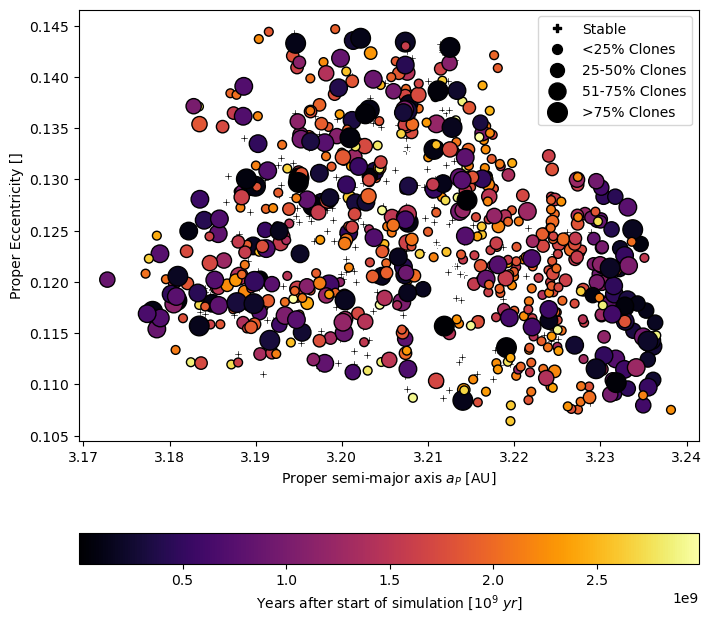

In [16]:
fig = plt.figure(figsize=(8, 8))
ax = plt.subplot(111)

flash_plot(ax, luth_fam, 'e_P')

plt.xlabel("Proper semi-major axis $a_P$ [AU]")
plt.ylabel("Proper Eccentricity []")
plt.show()

In [17]:
print(luth_fam[luth_fam.a_P <= 3.175])
print(luth_fam[luth_fam.a_P >= 3.237])

          abs_mag      a_P       e_P  sineI_P          n          g   
ast_name                                                              
2017AC51    17.41  3.17278  0.120229  0.32158  63.701778  85.871008  \

                  s  lyap_time  My_int_time      irad       ideg     diam   
ast_name                                                                    
2017AC51 -71.650735       14.9          -10  0.327397  18.758473  2.22674  \

          integration_year  quartiles graph_symbol  
ast_name                                            
2017AC51      8.735216e+08        3.0            o  
          abs_mag       a_P      e_P   sineI_P          n           g   
ast_name                                                                
2014YV40    16.09  3.238196  0.10752  0.317637  61.765176  361.322776  \

                  s  lyap_time  My_int_time      irad       ideg      diam   
ast_name                                                                     
2014YV40 -75.228371

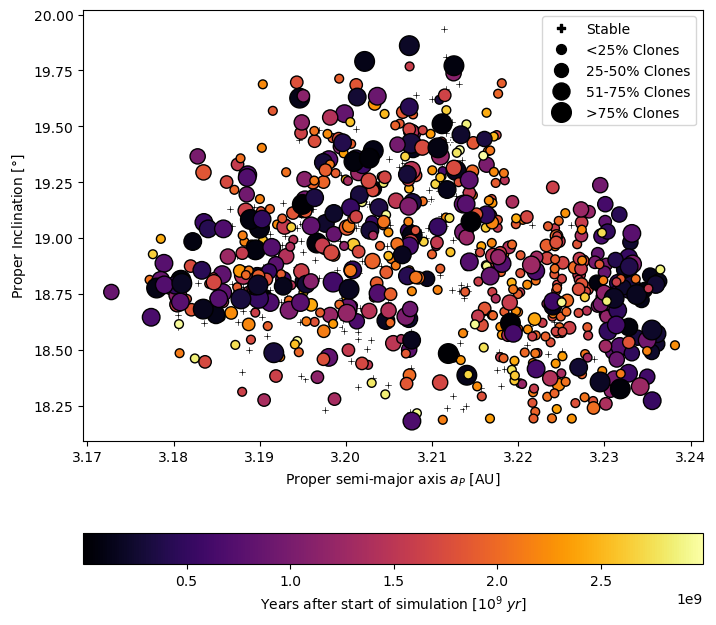

In [18]:
fig = plt.figure(figsize=(8, 8))
ax = plt.subplot(111)

flash_plot(ax, luth_fam, 'ideg')
    
plt.xlabel("Proper semi-major axis $a_P$ [AU]")
plt.ylabel("Proper Inclination [$\degree$]")
plt.show()

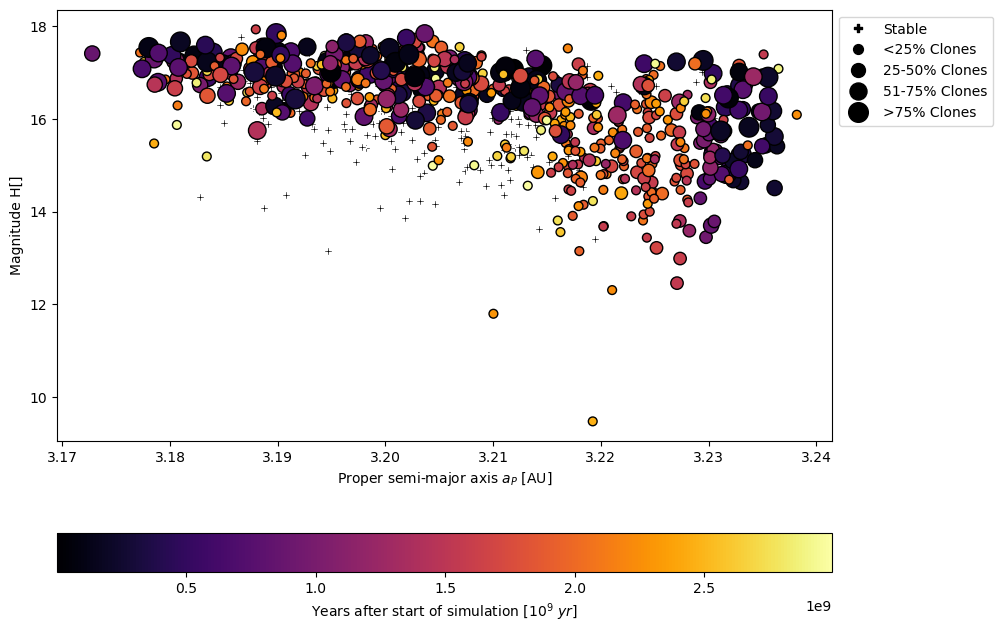

In [19]:
fig = plt.figure(figsize=(10, 8))
ax = plt.subplot(111)

flash_plot(ax, luth_fam, 'abs_mag')
    
plt.xlabel("Proper semi-major axis $a_P$ [AU]")
plt.ylabel("Magnitude H[]")
plt.show()

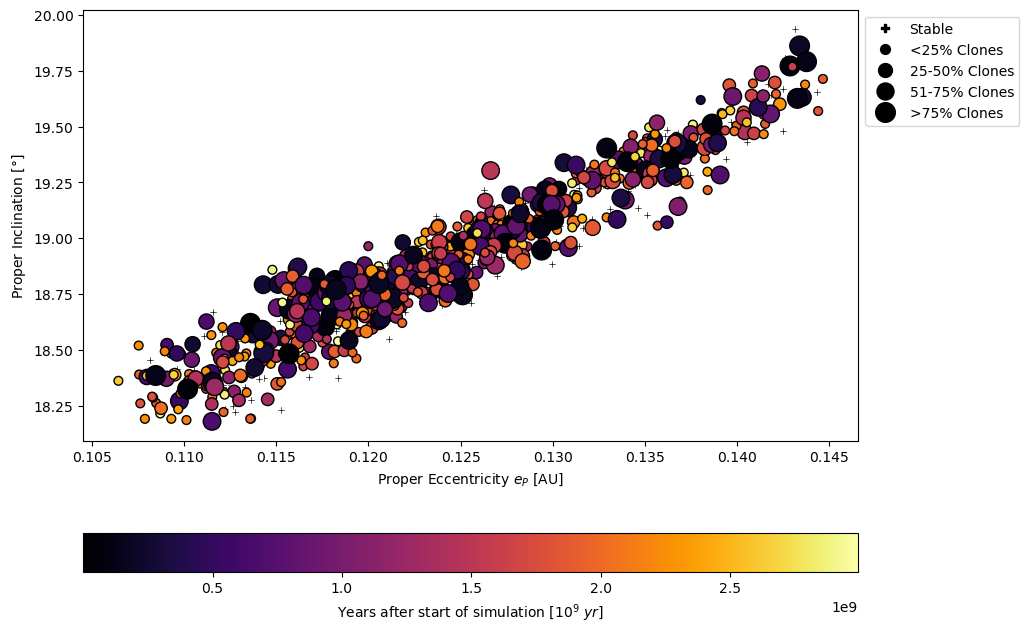

In [20]:
fig = plt.figure(figsize=(10, 8))
ax = plt.subplot(111)

flash_plot(ax, luth_fam, 'ideg', 'e_P')
    
plt.xlabel("Proper Eccentricity $e_P$ [AU]")
plt.ylabel("Proper Inclination [$\degree$]")
plt.show()

In [21]:
def hist_ratio(data, col_name, x_label):
    stable_cnts, bins = np.histogram(data[data.integration_year == 0][col_name],bins='auto')  
    escp_cnts, bins = np.histogram(data[data.integration_year != 0][col_name],bins=bins)
    ratio = ((stable_cnts)/(stable_cnts+escp_cnts+1.0e-40))*100

    fig = plt.figure(figsize=(8, 8))
    ax0 = plt.subplot(111)
    ax1 = ax0.twinx()
    ax0.hist([data[data.integration_year == 0][col_name], 
                  data[data.integration_year != 0][col_name]], bins=bins, stacked=True)
    ax0.set_ylabel("Frequency")
    ax0.set_xlabel(x_label)
    ax0.legend(labels=['Stable', 'Escaped'])


    ax1.plot(bins[:-1]+(bins[1]-bins[0])/2,ratio, c='grey', marker='+')
    ax1.set_ylim(0,100)
    ax1.set_ylabel("Asteroid Stability [%]")
    plt.show()
    

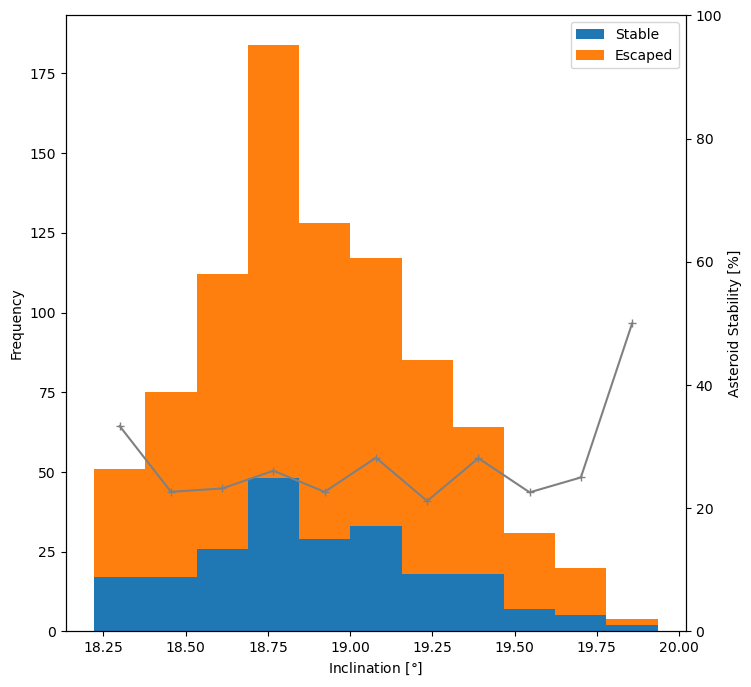

In [22]:
hist_ratio(luth_fam, 'ideg', "Inclination [$\degree$]")

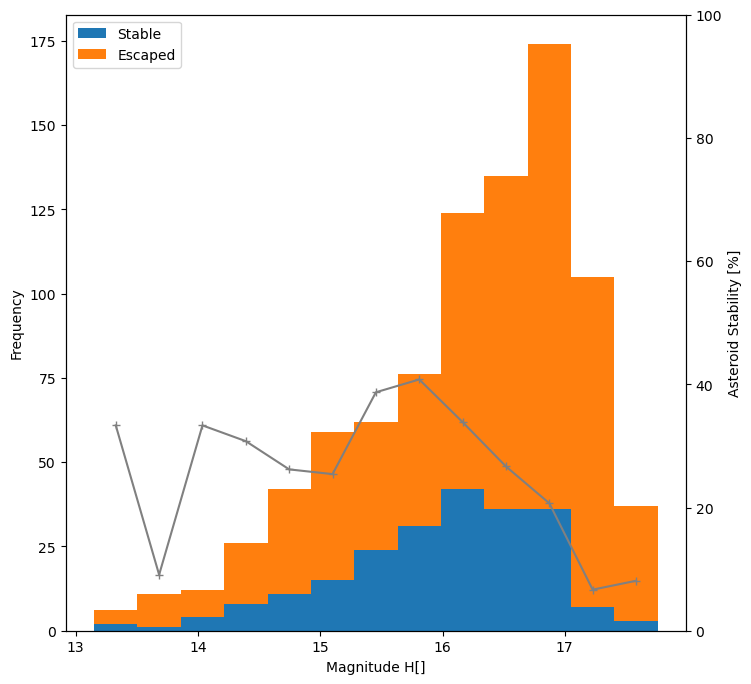

In [23]:
hist_ratio(luth_fam, 'abs_mag', "Magnitude H[]")

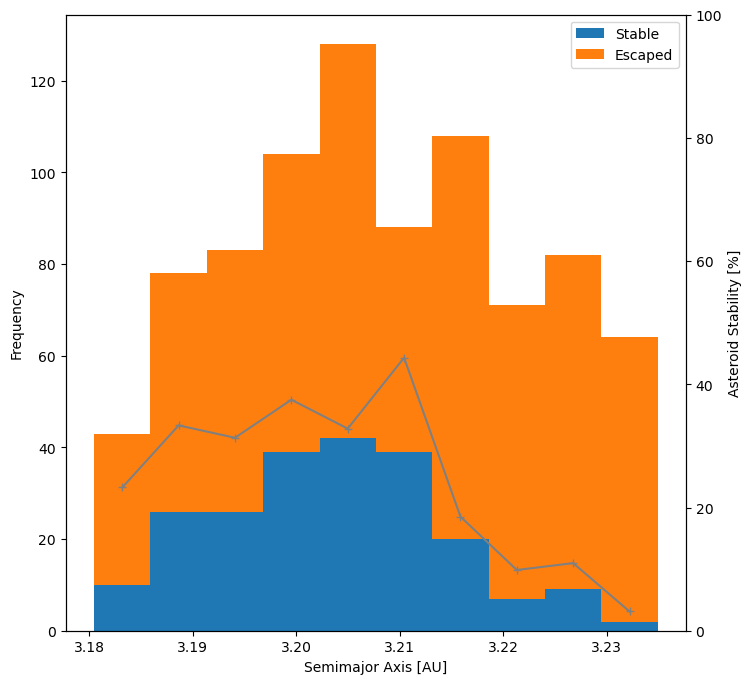

In [24]:
hist_ratio(luth_fam, 'a_P', "Semimajor Axis [AU]")

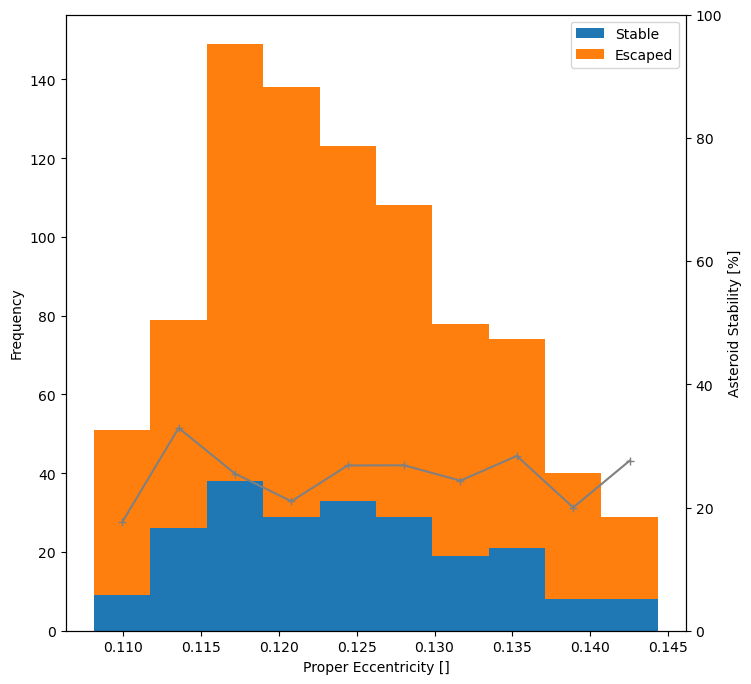

In [25]:
hist_ratio(luth_fam, 'e_P', "Proper Eccentricity []")

In [26]:
def ploto_loco(ax, ast_data, y_column, x_column, groupby, symbols, colors, edgecolors, legend):
    for last_sma, m_fam in ast_data.groupby(groupby):
        ax.scatter(data=m_fam, x=x_column,y=y_column, edgecolors=edgecolors[last_sma], marker=symbols[last_sma], 
                        c=colors[last_sma], s=25, label= legend[last_sma])


In [27]:
#luth_fam['min_sma'] = ea_mmc3.min_val
#luth_fam['max_sma'] = ea_mmc3.max_val
a_min = 1.8
a_max = 3.95
# 1 = inner
# 2 = outer
def inny_outy(esc):
    if esc.mean_min_val < a_min:
        return 1
    elif esc.mean_max_val > a_max:
        return 2
    else:
        return 0

max_min_sma = ea_mmc3.loc[ea_mmc3.parameter == 6][['min_val', 'max_val']]
mean_sma = max_min_sma.groupby(by=max_min_sma.index).mean(['min_val','max_val'])

luth_fam['mean_min_val'] = mean_sma.min_val
luth_fam['mean_max_val'] = mean_sma.max_val
luth_fam['last_sma'] = luth_fam.apply(inny_outy, axis=1)

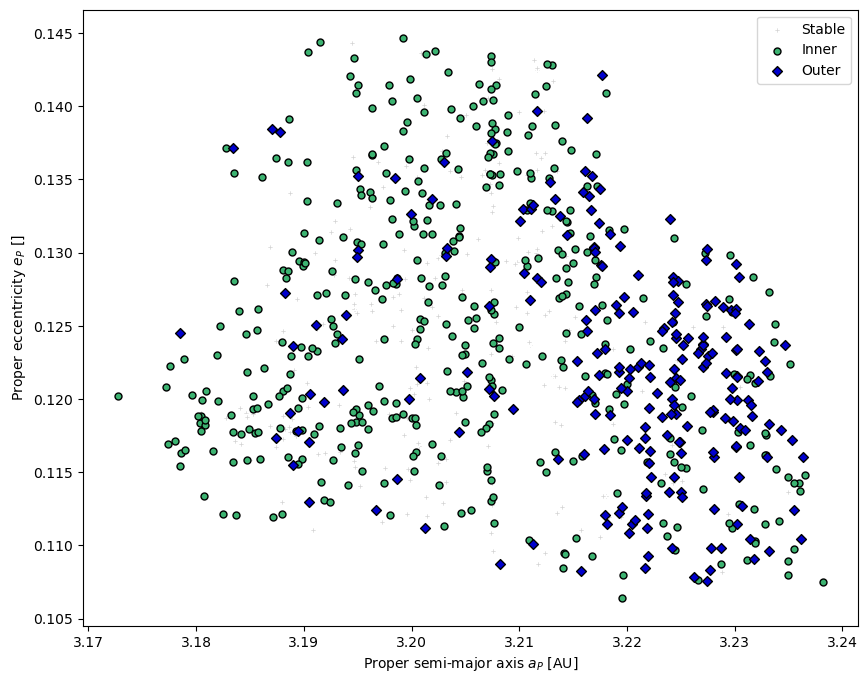

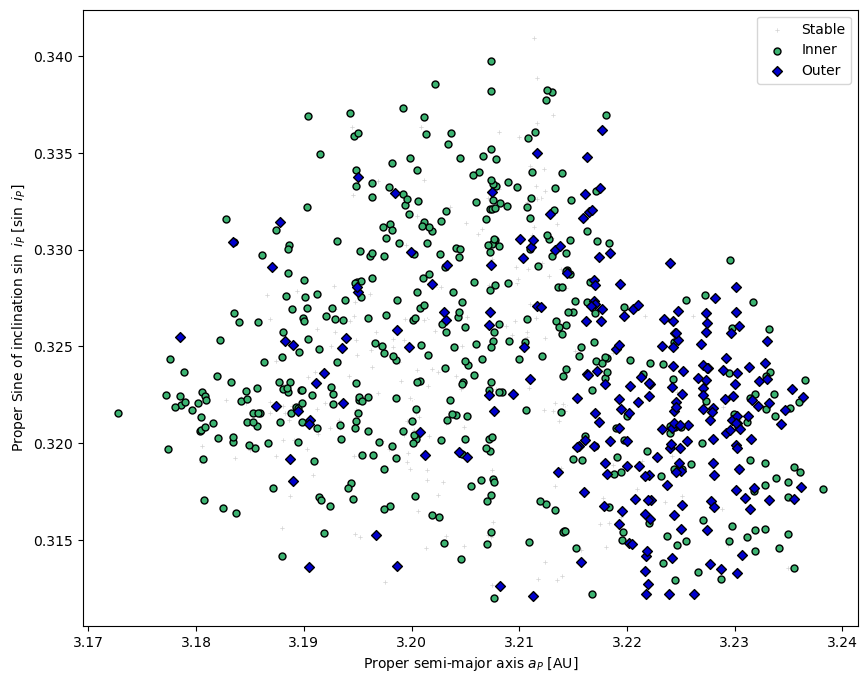

In [28]:
fig = plt.figure(figsize=(10, 8))
ax = plt.subplot(111)
symbols = ['P','o','D']
colors = ['lightgray','mediumseagreen', 'mediumblue']
edgecolors = ['white','black','black']
legend = ['Stable', 'Inner', 'Outer']

ploto_loco(ax, luth_fam, 'e_P', 'a_P', 'last_sma', symbols, colors, edgecolors, legend)
plt.legend()
plt.xlabel("Proper semi-major axis $a_P$ [AU]")
plt.ylabel("Proper eccentricity $e_P$ []")

plt.show()

fig = plt.figure(figsize=(10, 8))
ax = plt.subplot(111)
ploto_loco(ax, luth_fam, 'sineI_P', 'a_P', 'last_sma', symbols, colors, edgecolors, legend)
plt.legend()
plt.xlabel("Proper semi-major axis $a_P$ [AU]")
plt.ylabel("Proper Sine of inclination $\sin ~i_P$ [$\sin ~i_P$]")
plt.show()


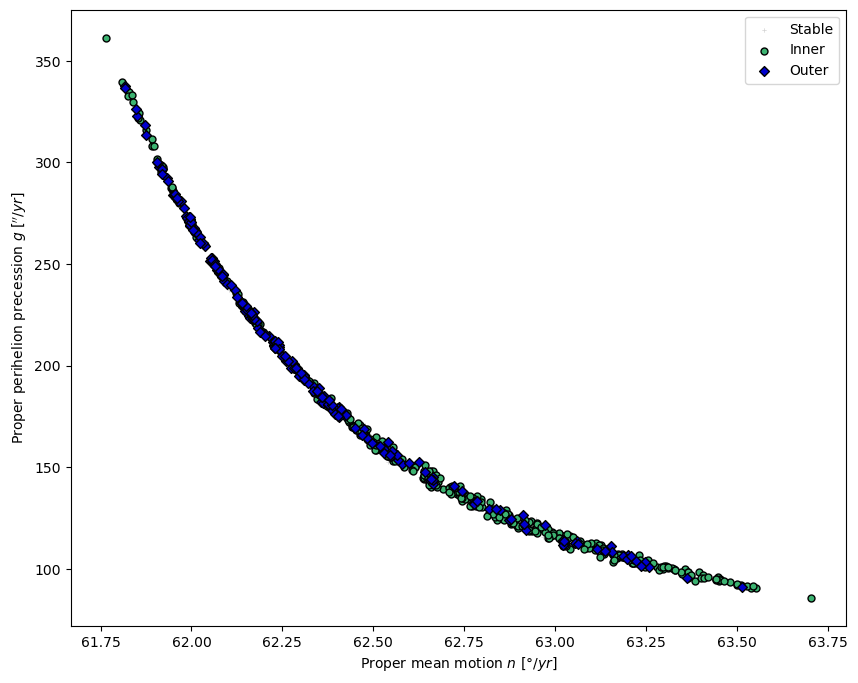

In [29]:

fig = plt.figure(figsize=(10, 8))
ax = plt.subplot(111)
ploto_loco(ax, luth_fam, 'g', 'n', 'last_sma', symbols, colors, edgecolors, legend)
plt.legend()
plt.xlabel("Proper mean motion $n$ [$\degree / yr$]")
plt.ylabel("Proper perihelion precession $g$ [$''/yr$]")
plt.show()


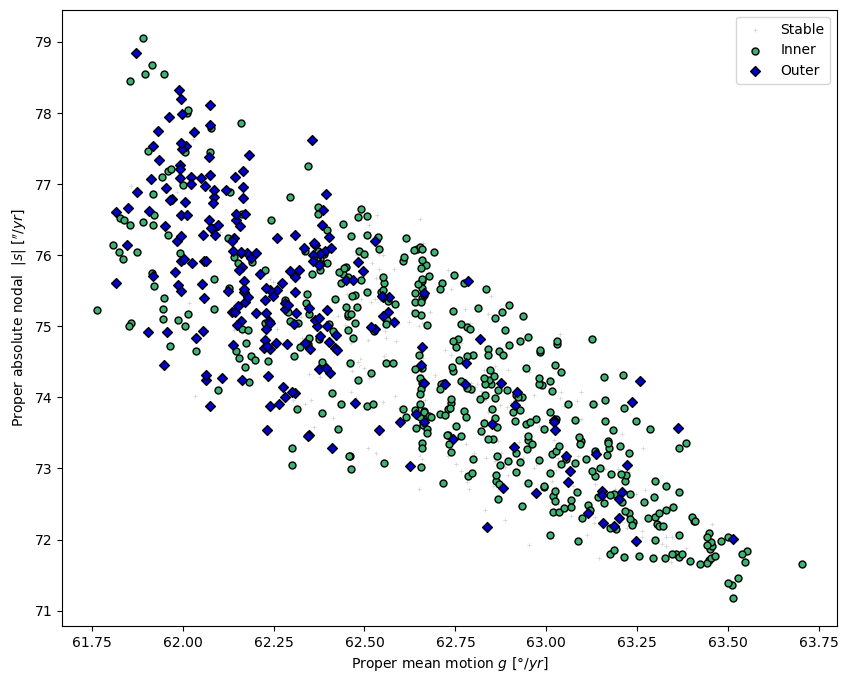

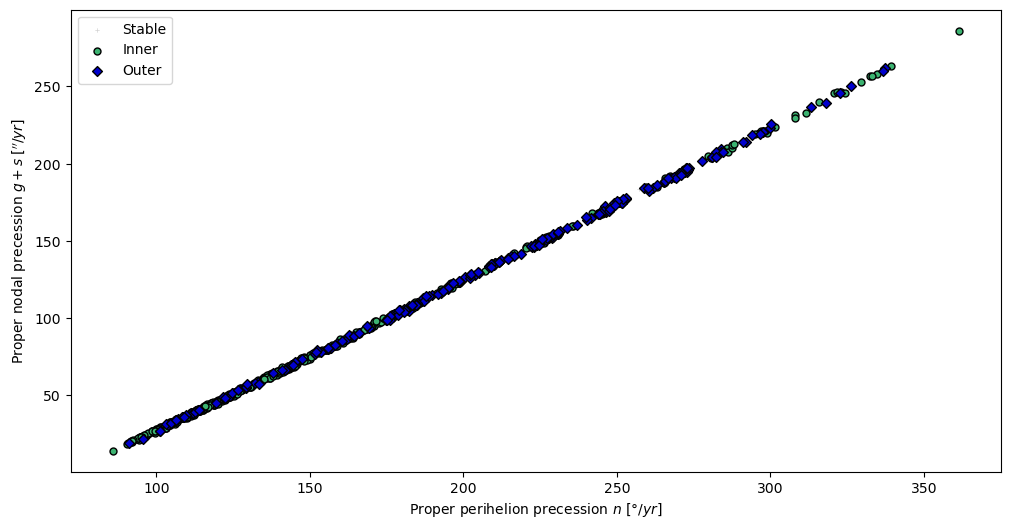

In [30]:
luth_fam['g_s'] = luth_fam.g + luth_fam.s
luth_fam['abs_s'] = np.absolute(luth_fam.s)

fig = plt.figure(figsize=(10, 8))
ax = plt.subplot(111)
ploto_loco(ax, luth_fam, 'abs_s', 'n', 'last_sma', symbols, colors, edgecolors, legend)
plt.legend()
plt.xlabel("Proper mean motion $g$ [$\degree / yr$]")
plt.ylabel("Proper absolute nodal  $|s|$ [$''/yr$]")
plt.show()

fig = plt.figure(figsize=(12, 6))
ax = plt.subplot(111)
ploto_loco(ax, luth_fam, 'g_s', 'g', 'last_sma', symbols, colors, edgecolors, legend)
plt.legend()
plt.xlabel("Proper perihelion precession $n$ [$\degree / yr$]")
plt.ylabel("Proper nodal precession $g+s$ [$''/yr$]")
plt.show()



In [31]:
luth_fam[luth_fam.a_P < 3.179].sort_values('g')

,abs_mag,a_P,e_P,sineI_P,n,g,s,lyap_time,My_int_time,irad,ideg,diam,integration_year,quartiles,graph_symbol,mean_min_val,mean_max_val,last_sma,g_s,abs_s
ast_name,,,,,,,,,,,,,,,,,,,,
2017AC51,17.41,3.172780,0.120229,0.321580,63.701778,85.871008,-71.650735,14.9,-10,0.327397,18.758473,2.226740,8.735216e+08,3.0,o,0.000000,16.080645,1,14.220273,71.650735
2011ES49,17.23,3.177599,0.122272,0.324373,63.538455,90.535587,-71.798850,68.0,-10,0.330349,18.927587,2.419187,2.644762e+09,1.0,o,0.000000,3.089769,1,18.736737,71.798850
2010ET174,17.43,3.177220,0.120810,0.322482,63.550885,90.793914,-71.831970,58.8,-10,0.328351,18.813117,2.206325,2.049678e+09,1.0,o,0.000000,3.201970,1,18.961944,71.831970
330823,15.47,3.178524,0.124519,0.325508,63.511943,91.111543,-72.014037,204.1,-10,0.331549,18.996373,5.440884,2.438108e+09,1.0,o,1.989088,18.093398,2,19.097506,72.014037
2015MD194,17.54,3.178033,0.117138,0.321873,63.526958,91.646419,-71.459561,131.6,-10,0.327707,18.776228,2.097343,1.067229e+08,5.0,o,0.000000,2.835547,1,20.186858,71.459561
2015BL268,17.29,3.178525,0.115409,0.322445,63.512027,91.864279,-71.181669,238.1,-10,0.328311,18.810847,2.353258,8.760731e+08,4.0,o,0.000000,13.626327,1,20.682610,71.181669
2019JK107,17.08,3.177404,0.116901,0.319711,63.544640,91.877447,-71.678005,56.8,-10,0.325424,18.645436,2.592206,6.603515e+08,4.0,o,0.000000,3.016347,1,20.199442,71.678005
2010LV19,16.74,3.178582,0.116273,0.321966,63.510304,92.149982,-71.359988,192.3,-10,0.327806,18.781874,3.031583,1.465089e+09,3.0,o,0.000000,11.076108,1,20.789994,71.359988
2010HU44,16.79,3.178887,0.122752,0.323702,63.499657,92.169207,-72.035109,36.9,-10,0.329639,18.886949,2.962576,7.503427e+08,4.0,o,0.000000,2.360993,1,20.134098,72.035109
